## Home credit risk project: Manual data wrangling and model analysis

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
pd.set_option('display.max_rows', 10)
pd.set_option('display.min_rows', 6)

In [2]:
train = pd.read_csv('application_train.csv')
test = pd.read_csv('application_test.csv')

# Exploratory Data analysis (EDA)

In [3]:
train.TARGET.value_counts() # IMBALANCED CLASS PROBLEM

TARGET
0    282686
1     24825
Name: count, dtype: int64

In [4]:
def missing_values_table(df):
    leng = len(df)
    ls1 = []
    ls2 = []
    for cols in df.columns:
        
        per = df[cols].isnull().sum() / leng
        ls1.append(cols)
        ls2.append(per)

    return pd.Series(ls2, index=ls1)

msvt = missing_values_table(train).sort_values(ascending=False)

idx = msvt.loc[msvt == 0].index[0]
print(f'There are {len(msvt.loc[:idx])-1} columns with missing values' )
msvt
    
    

There are 67 columns with missing values


COMMONAREA_MEDI        0.698723
COMMONAREA_AVG         0.698723
COMMONAREA_MODE        0.698723
                         ...   
NAME_EDUCATION_TYPE    0.000000
NAME_INCOME_TYPE       0.000000
SK_ID_CURR             0.000000
Length: 122, dtype: float64

In [5]:
train.dtypes.value_counts()

float64    65
int64      41
object     16
Name: count, dtype: int64

In [6]:
# Unique values per object column
train.select_dtypes(include='object').apply(pd.Series.nunique, axis=0)

NAME_CONTRACT_TYPE     2
CODE_GENDER            3
FLAG_OWN_CAR           2
                      ..
HOUSETYPE_MODE         3
WALLSMATERIAL_MODE     7
EMERGENCYSTATE_MODE    2
Length: 16, dtype: int64

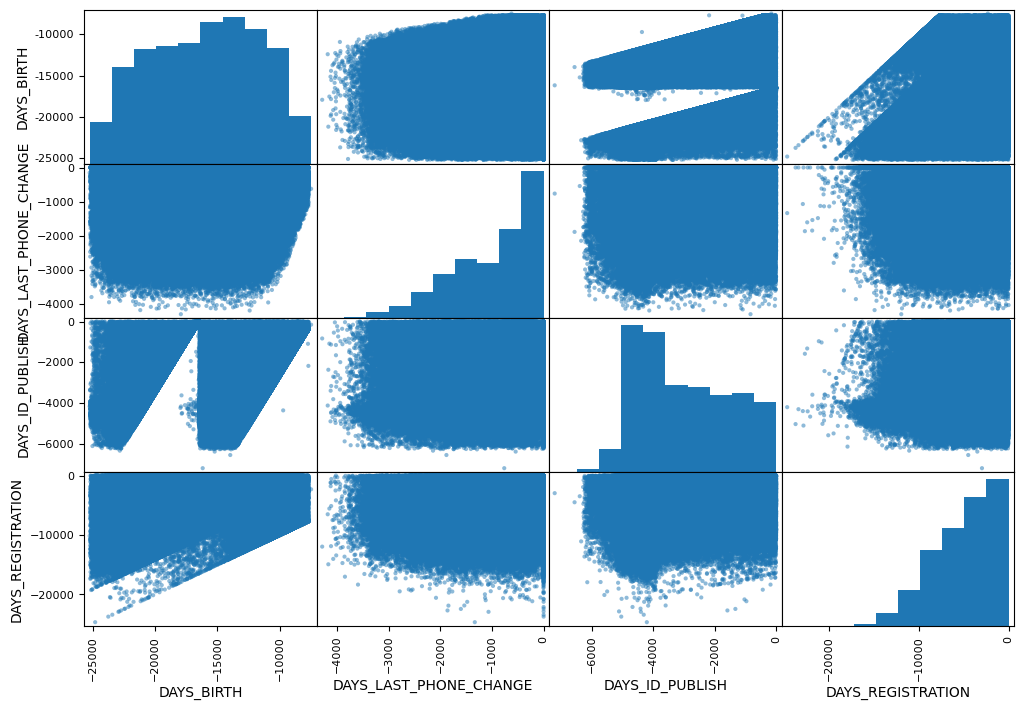

In [7]:
corrM = train.corr(numeric_only=True)
TM = corrM['TARGET'].sort_values(ascending=False)
attributes = TM.iloc[1:11].index 
numeric_like = [c for c in attributes if train[c].nunique() > 60] # crude but effective filter
pd.plotting.scatter_matrix(train[numeric_like[:4]], figsize=(12, 8));

# Encoding Categorical data

In [8]:
"""
We implement the following poilicy:
Categorical data with 2 unique values ------> Label/Ordinal encoding
Categorical data with k>2 unique values ------> OH encoding
"""
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

OH_encoder = OneHotEncoder()
Ord_encoder = OrdinalEncoder()

cat_var = train.select_dtypes(include='object')
num_var = train.select_dtypes(exclude='object')

cat_var = cat_var.fillna('Missing')   # <-- turn NaN into its own explicit category, up front
                                      # That way we treat NaN as it's own category

OH_list = []
Ord_list = []
for col in cat_var.columns:
    if cat_var[col].nunique() > 2:
        OH_list.append(col)
    else:
        Ord_list.append(col)

OH_data = cat_var.drop(Ord_list, axis=1)
Ord_data = cat_var.drop(OH_list, axis=1)

Ord_trans = pd.DataFrame(Ord_encoder.fit_transform(Ord_data), columns=Ord_data.columns, index=Ord_data.index)

OH_transformed = OH_encoder.fit_transform(OH_data)
OH_trans = pd.DataFrame(
    OH_transformed.toarray(), 
    columns=OH_encoder.get_feature_names_out(), 
    index=OH_data.index
)

cat_var = pd.concat([Ord_trans, OH_trans], axis=1)
train_trans = pd.concat([cat_var, num_var], axis=1)
y_train = train_trans.TARGET
train_trans = train_trans.drop(['TARGET'], axis=1)
train_trans


,NAME_CONTRACT_TYPE,FLAG_OWN_CAR,FLAG_OWN_REALTY,CODE_GENDER_F,CODE_GENDER_M,CODE_GENDER_XNA,NAME_TYPE_SUITE_Children,NAME_TYPE_SUITE_Family,NAME_TYPE_SUITE_Group of people,NAME_TYPE_SUITE_Missing,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307508,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0
307509,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
307510,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0.0,0.0,0.0,2.0,0.0,1.0


In [9]:
# We make the same transformation to test data

test_cat_var = test.select_dtypes(include='object')
test_num_var = test.select_dtypes(exclude='object')

test_cat_var = test_cat_var.fillna('Missing')   # same explicit-missing-category treatment as train

test_OH_data = test_cat_var[OH_list]
test_Ord_data = test_cat_var[Ord_list]

# .transform() only -- reuse the encoders already fit on train in Cell 10
test_Ord_trans = pd.DataFrame(
    Ord_encoder.transform(test_Ord_data),
    columns=test_Ord_data.columns, index=test_Ord_data.index
)

test_OH_transformed = OH_encoder.transform(test_OH_data)
test_OH_trans = pd.DataFrame(
    test_OH_transformed.toarray(),
    columns=OH_encoder.get_feature_names_out(),
    index=test_OH_data.index
)

test_cat_var = pd.concat([test_Ord_trans, test_OH_trans], axis=1)
test_trans = pd.concat([test_cat_var, test_num_var], axis=1)
test_trans

,NAME_CONTRACT_TYPE,FLAG_OWN_CAR,FLAG_OWN_REALTY,CODE_GENDER_F,CODE_GENDER_M,CODE_GENDER_XNA,NAME_TYPE_SUITE_Children,NAME_TYPE_SUITE_Family,NAME_TYPE_SUITE_Group of people,NAME_TYPE_SUITE_Missing,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
2,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48741,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,3.0,1.0
48742,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,2.0
48743,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,4.0


In [10]:
X_train = train_trans.copy()
X_test = test_trans.copy()
y_train

0         1
1         0
2         0
         ..
307508    0
307509    1
307510    0
Name: TARGET, Length: 307511, dtype: int64

# Back to exploratory analysis

In [11]:
(X_train['DAYS_BIRTH'] / -365).describe()

count    307511.000000
mean         43.936973
std          11.956133
min          20.517808
25%          34.008219
50%          43.150685
75%          53.923288
max          69.120548
Name: DAYS_BIRTH, dtype: float64

958.9041095890411<------- # years employed? Clearly anomalous
The non-anomalies default on 8.66% of loans
The anomalies default on 5.40% of loans
There are 55374 anomalous days of employment values


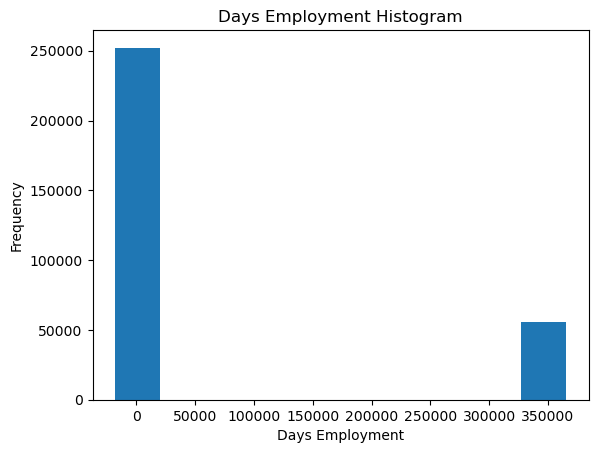

In [12]:
X_train['DAYS_EMPLOYED'].plot.hist(title = 'Days Employment Histogram');
plt.xlabel('Days Employment');
print(f'{350000/365}<------- # years employed? Clearly anomalous')
anom = X_train[X_train['DAYS_EMPLOYED'] == 365243]
non_anom = X_train[X_train['DAYS_EMPLOYED'] != 365243]
print('The non-anomalies default on %0.2f%% of loans' % (100 * y_train.loc[non_anom.index].mean()))
print('The anomalies default on %0.2f%% of loans' % (100 * y_train.loc[anom.index].mean()))
print('There are %d anomalous days of employment values' % len(anom))

In [13]:
X_train['DAYS_EMPLOYED'].describe()

count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

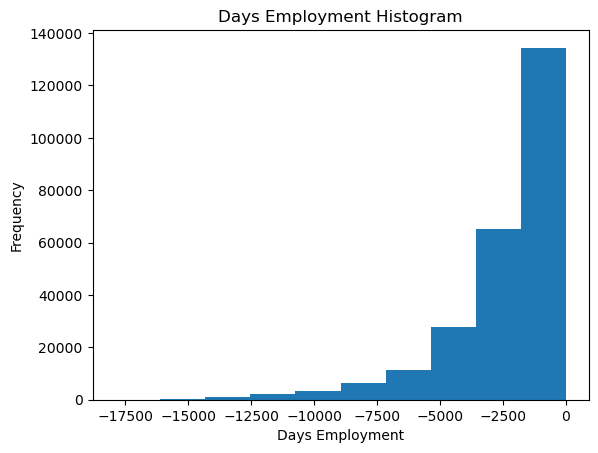

In [14]:
# Being or not anomalous clearly has weight on default rate predictions thus we take those as NaN's
# then imputate with a column declaring anomality

X_train['DAYS_EMPLOYED_ANOM'] = (X_train['DAYS_EMPLOYED'] == 365243)
X_train['DAYS_EMPLOYED'] = X_train['DAYS_EMPLOYED'].replace(365243, np.nan)

X_test['DAYS_EMPLOYED_ANOM'] = (X_test['DAYS_EMPLOYED'] == 365243)
X_test['DAYS_EMPLOYED'] = X_test['DAYS_EMPLOYED'].replace(365243, np.nan)

X_train['DAYS_BIRTH'] = np.abs(X_train['DAYS_BIRTH']) # Age is negative
X_test['DAYS_BIRTH'] = np.abs(X_test['DAYS_BIRTH'])

X_train['DAYS_EMPLOYED'].plot.hist(title = 'Days Employment Histogram');
plt.xlabel('Days Employment');

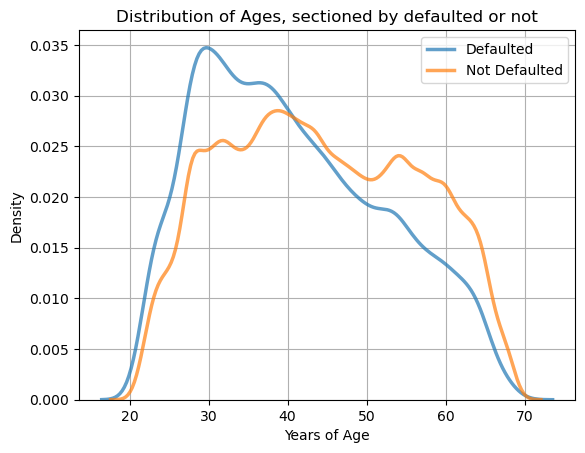

In [15]:
def_inex = y_train.loc[y_train == 1].index
ndef_inex = y_train.loc[y_train == 0].index

sns.kdeplot(x=(X_train.DAYS_BIRTH.loc[def_inex]) /365, fill=False, alpha=0.7, linewidth=2.5, label='Defaulted')
sns.kdeplot(x=(X_train.DAYS_BIRTH.loc[ndef_inex]) /365, fill=False, alpha=0.7, linewidth=2.5, label='Not Defaulted')

plt.grid()
plt.legend()
plt.xlabel('Years of Age')
plt.title('Distribution of Ages, sectioned by defaulted or not');

In [16]:
corrM = pd.concat([X_train, y_train], axis=1).corr(numeric_only=True)
TM = corrM['TARGET'].sort_values(ascending=False)
TM.head(7), TM.tail(7) # CLEARLY ext_source k has the highest absolute correlation

(TARGET                         1.000000
 DAYS_EMPLOYED                  0.074958
 REGION_RATING_CLIENT_W_CITY    0.060893
 REGION_RATING_CLIENT           0.058899
 NAME_INCOME_TYPE_Working       0.057481
 DAYS_LAST_PHONE_CHANGE         0.055218
 CODE_GENDER_M                  0.054713
 Name: TARGET, dtype: float64,
 NAME_INCOME_TYPE_Pensioner             -0.046209
 CODE_GENDER_F                          -0.054704
 NAME_EDUCATION_TYPE_Higher education   -0.056593
 DAYS_BIRTH                             -0.078239
 EXT_SOURCE_1                           -0.155317
 EXT_SOURCE_2                           -0.160472
 EXT_SOURCE_3                           -0.178919
 Name: TARGET, dtype: float64)

<Axes: >

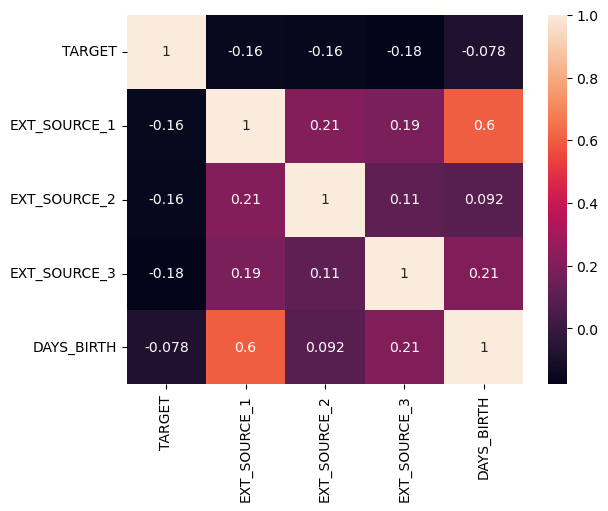

In [19]:
EXT_SOURCE_data = pd.concat([y_train, X_train[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_BIRTH']]], axis=1)
sns.heatmap(data=EXT_SOURCE_data.corr(), annot=True)

c:\ProgramData\anaconda3\Lib\site-packages\seaborn\distributions.py:1128: UserWarning: cmap parameter ignored when using hue mapping.
  warnings.warn(msg, UserWarning)
c:\ProgramData\anaconda3\Lib\site-packages\seaborn\distributions.py:1128: UserWarning: cmap parameter ignored when using hue mapping.
  warnings.warn(msg, UserWarning)
c:\ProgramData\anaconda3\Lib\site-packages\seaborn\distributions.py:1128: UserWarning: cmap parameter ignored when using hue mapping.
  warnings.warn(msg, UserWarning)
c:\ProgramData\anaconda3\Lib\site-packages\seaborn\distributions.py:1128: UserWarning: cmap parameter ignored when using hue mapping.
  warnings.warn(msg, UserWarning)
c:\ProgramData\anaconda3\Lib\site-packages\seaborn\distributions.py:1128: UserWarning: cmap parameter ignored when using hue mapping.
  warnings.warn(msg, UserWarning)
c:\ProgramData\anaconda3\Lib\site-packages\seaborn\distributions.py:1128: UserWarning: cmap parameter ignored when using hue mapping.
  warnings.warn(msg, UserW

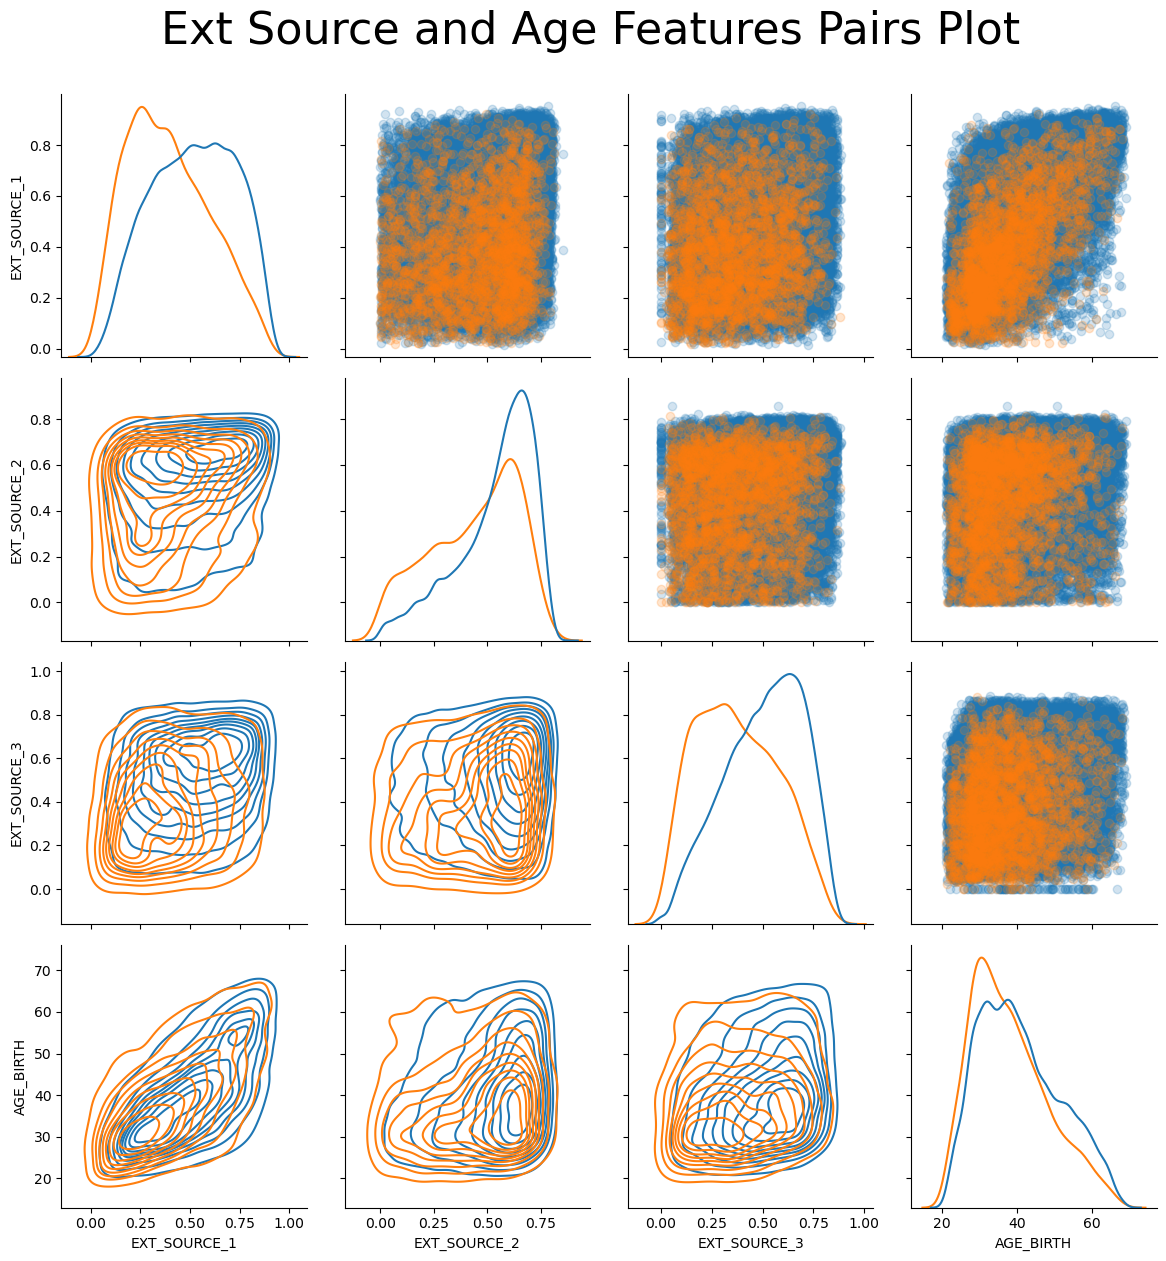

In [25]:
plot_data = EXT_SOURCE_data.drop(['DAYS_BIRTH'], axis=1).copy()
plot_data['AGE_BIRTH'] = X_train['DAYS_BIRTH'] / 365
plot_data['TARGET'] = y_train                      # bring the target in as a genuine column, aligned by index
plot_data = plot_data.dropna().loc[:100000, :]

grid = sns.PairGrid(
    data=plot_data,
    height=3,
    diag_sharey=False,
    hue='TARGET',
    vars=[x for x in plot_data.columns if x != 'TARGET']
)

# Upper triangle: scatter plots
grid.map_upper(plt.scatter, alpha=0.2)

# Diagonal: KDE of each variable's own distribution, normalized independently per class
grid.map_diag(sns.kdeplot, common_norm=False)

# Lower triangle: 2D density plots, also normalized independently per class
grid.map_lower(sns.kdeplot, cmap=plt.cm.OrRd_r, common_norm=False)

plt.suptitle('Ext Source and Age Features Pairs Plot', size=32, y=1.05);
plt.show()

# Featrue engineering